Аппроксимация функции $x^2$

$x \in (10^{-15}, 1]$

Для начала пошагово повторю пример из лекции

In [4]:
import math

import numpy as np
import pandas as pd
import torch
from data import get_data
from plots import plot_MAPE_optimizer, plot_MAPE_batch, plot_MAPE_neurons
from matplotlib import pyplot as plt
from models import MLP, MLP3
from torch import nn, optim
from train import run

x_train, y_train, x_val, y_val = get_data()
torch.manual_seed(42)

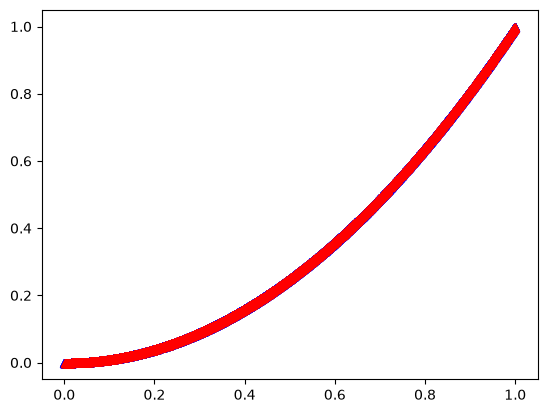

In [7]:
plt.figure("train")
plt.plot(x_train.numpy(), y_train.numpy(), "b", lw=0, marker="^")
plt.plot(x_val.numpy(), y_val.numpy(), "r", lw=0, marker="^")
plt.show()


- 2 слоя: 1 –50 –1
- Relu
- batch=128
- epoch=200
- Adam (lr=0.001)
- без изменения lr
- Loss: MSE

MSE: 9.603830221749377e-06, MAPE: 3.6561503410339355


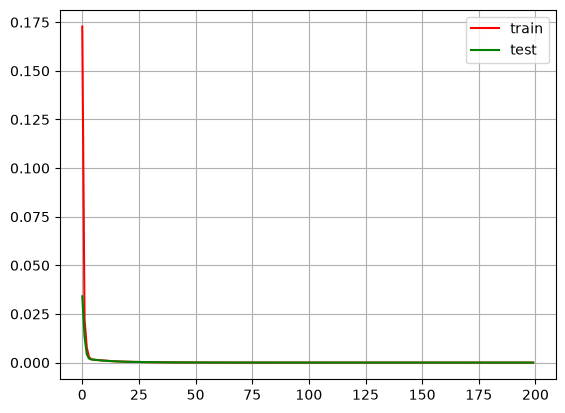

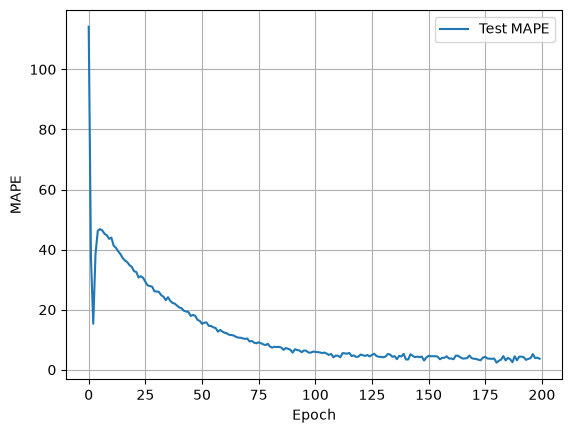

In [8]:
model = MLP()
batch_size = 128
n_epoch = 200
lr = 0.001

# Defines a optimizer to update the parameters
optimizer = optim.Adam(model.parameters(), lr=lr)
model_loss = nn.MSELoss()

train_errors, test_errors, test_mapes = run(model, model_loss, optimizer, x_train, y_train, x_val, y_val, n_epoch, batch_size)

print(f"MSE: {test_errors[-1][1]}, MAPE: {test_mapes[-1][1]}")

plt.figure("Errors")
train_errors = np.array(train_errors)
test_errors = np.array(test_errors)
plt.plot(train_errors[:,0],train_errors[:,1],"r-",label = "train")
plt.plot(test_errors[:,0],test_errors[:,1],"g-",label = "test")
plt.legend()
plt.grid()
plt.show()

test_mapes = np.array(test_mapes)
plt.plot(test_mapes[:,0], test_mapes[:,1], label="Test MAPE")
plt.xlabel("Epoch")
plt.ylabel("MAPE")
plt.legend()
plt.grid()
plt.show()

- 2 слоя: 1 –50 –1
- Relu
- batch=512
- epoch=200
- Adam (lr=0.001)
- без изменения lr
- Loss: MSE

MSE: 4.867275492870249e-06, MAPE: 3.156904697418213


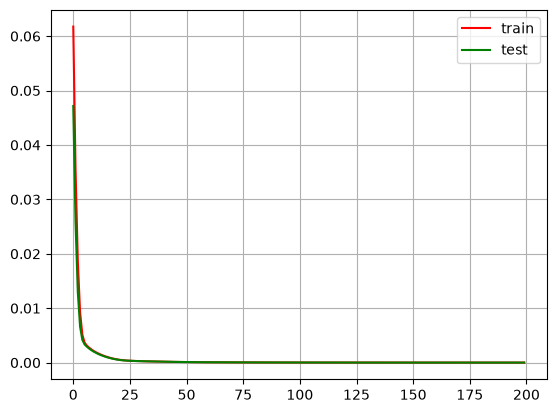

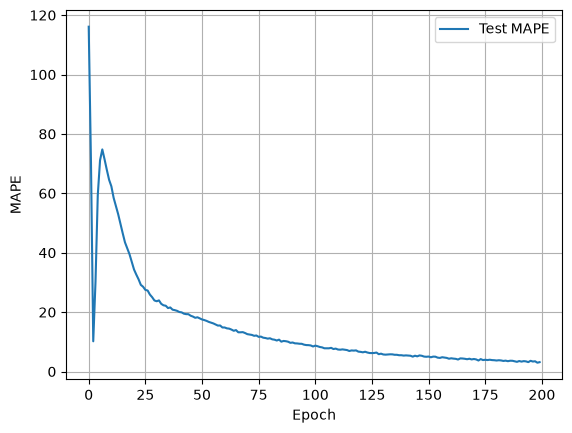

In [9]:
model = MLP()
batch_size = 512
n_epoch = 200
lr = 0.001

# Defines a optimizer to update the parameters
optimizer = optim.Adam(model.parameters(), lr=lr)
model_loss = nn.MSELoss()

train_errors, test_errors, test_mapes = run(model, model_loss, optimizer, x_train, y_train, x_val, y_val, n_epoch, batch_size)

print(f"MSE: {test_errors[-1][1]}, MAPE: {test_mapes[-1][1]}")

plt.figure("Errors")
train_errors = np.array(train_errors)
test_errors = np.array(test_errors)
plt.plot(train_errors[:,0],train_errors[:,1],"r-",label = "train")
plt.plot(test_errors[:,0],test_errors[:,1],"g-",label = "test")
plt.legend()
plt.grid()
plt.show()

test_mapes = np.array(test_mapes)
plt.plot(test_mapes[:,0], test_mapes[:,1], label="Test MAPE")
plt.xlabel("Epoch")
plt.ylabel("MAPE")
plt.legend()
plt.grid()
plt.show()

Реализация сэмплирования пакетов с помощью распределения весов на более мелкие x

- batch=128
- epoch=200
- Adam (lr=0.001)
- без изменения lr

MSE: 4.178672043053666e-06, MAPE: 2.0035321712493896


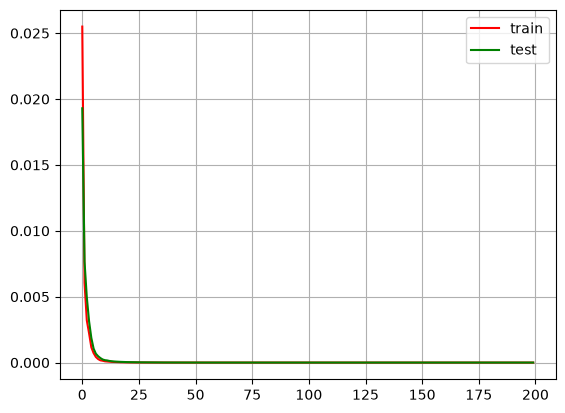

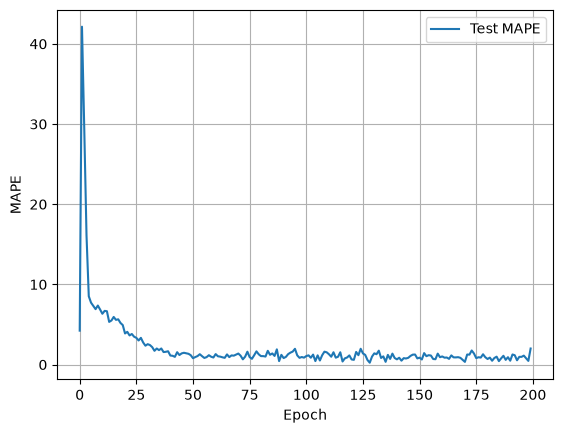

In [10]:
model = MLP()
batch_size = 128
n_epoch = 200
lr = 0.001

# Defines a optimizer to update the parameters
optimizer = optim.Adam(model.parameters(), lr=lr)
model_loss = nn.MSELoss()

train_errors, test_errors, test_mapes = run(model, model_loss, optimizer, x_train, y_train, x_val, y_val, n_epoch, batch_size, sampling=True)

print(f"MSE: {test_errors[-1][1]}, MAPE: {test_mapes[-1][1]}")

plt.figure("Errors")
train_errors = np.array(train_errors)
test_errors = np.array(test_errors)
plt.plot(train_errors[:,0],train_errors[:,1],"r-",label = "train")
plt.plot(test_errors[:,0],test_errors[:,1],"g-",label = "test")
plt.legend()
plt.grid()
plt.show()

test_mapes = np.array(test_mapes)
plt.plot(test_mapes[:,0], test_mapes[:,1], label="Test MAPE")
plt.xlabel("Epoch")
plt.ylabel("MAPE")
plt.legend()
plt.grid()
plt.show()

- Изменение LR
- Cэмплированиепакетов
- batch=128
- epoch=400
- Adam (начальный lr=0.001)

MSE: 2.2839025405119173e-05, MAPE: 3.802746057510376


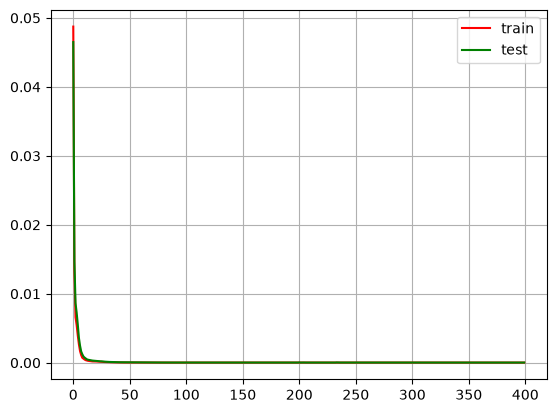

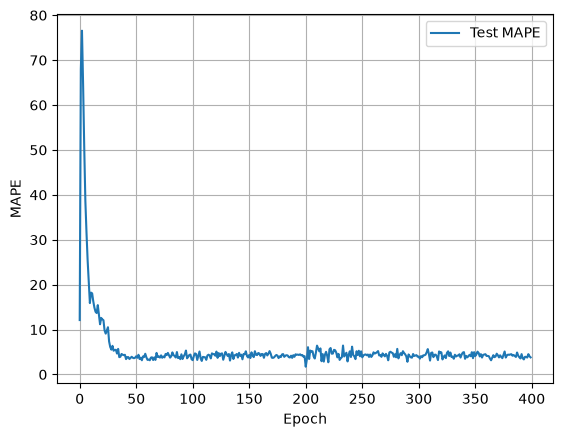

In [11]:
model = MLP()
batch_size = 128
n_epoch = 400
lr = 0.001

# Defines a optimizer to update the parameters
optimizer = optim.Adam(model.parameters(), lr=lr)
scheduler = optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda epoch: math.exp(-0.01 * (epoch % 200)),
)
model_loss = nn.MSELoss()

train_errors, test_errors, test_mapes = run(model, model_loss, optimizer, x_train, y_train, x_val, y_val, n_epoch, batch_size, sampling=True, scheduler=scheduler)

print(f"MSE: {test_errors[-1][1]}, MAPE: {test_mapes[-1][1]}")

plt.figure("Errors")
train_errors = np.array(train_errors)
test_errors = np.array(test_errors)
plt.plot(train_errors[:,0],train_errors[:,1],"r-",label = "train")
plt.plot(test_errors[:,0],test_errors[:,1],"g-",label = "test")
plt.legend()
plt.grid()
plt.show()

test_mapes = np.array(test_mapes)
plt.plot(test_mapes[:,0], test_mapes[:,1], label="Test MAPE")
plt.xlabel("Epoch")
plt.ylabel("MAPE")
plt.legend()
plt.grid()
plt.show()

In [12]:
model = MLP3()
batch_size = 128
n_epoch = 400
lr = 0.001

# Defines a optimizer to update the parameters
optimizer = optim.Adam(model.parameters(), lr=lr)
scheduler = optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda epoch: math.exp(-0.01 * (epoch % 200)),
)
model_loss = nn.MSELoss()

train_errors, test_errors, test_mapes = run(model, model_loss, optimizer, x_train, y_train, x_val, y_val, n_epoch, batch_size, sampling=True,scheduler=scheduler)

print(f"MSE: {test_errors[-1][1]}, MAPE: {test_mapes[-1][1]}")

plt.figure("Errors")
train_errors = np.array(train_errors)
test_errors = np.array(test_errors)
plt.plot(train_errors[:,0],train_errors[:,1],"r-",label = "train")
plt.plot(test_errors[:,0],test_errors[:,1],"g-",label = "test")
plt.legend()
plt.grid()
plt.show()

test_mapes = np.array(test_mapes)
plt.plot(test_mapes[:,0], test_mapes[:,1], label="Test MAPE")
plt.xlabel("Epoch")
plt.ylabel("MAPE")
plt.legend()
plt.grid()
plt.show()

KeyboardInterrupt: 

Восстановив код для примеров из презентации приступлю к пробам разных архитектур НС в том числе фукнции активации, затем можно сравнить функции потерь, а также использовать различные оптимизаторы.

In [ ]:
lr = 0.001
epochs = 200
batch_sizes = [32, 64, 128, 256, 512]

Решил, что можно просто прогнать все комбинации

In [ ]:
funcs = [nn.ReLU, nn.Sigmoid, nn.Tanh, nn.ELU, nn.LeakyReLU, nn.SiLU, nn.Mish]
model_losses = [nn.MSELoss(), nn.L1Loss()]
optimizers = {
    "Momentum": lambda params: optim.SGD(params, lr=lr, momentum=0.9),
    "Nesterov": lambda params: optim.SGD(params, lr=lr, momentum=0.9, nesterov=True),
    "Adagrad": lambda params: optim.Adagrad(params, lr=lr),
    "RMSprop": lambda params: optim.RMSprop(params, lr=lr),
    "Adadelta": lambda params: optim.Adadelta(params, lr=lr),
    "Adam": lambda params: optim.Adam(params, lr=lr),
}

Понял, что нужно сохранять результаты, чтобы не перегонять комбинации

Получается слишком много комбинаций, попробовал перенести на gpu вычисления, но выйграш отсутствовал. Принято решение распараллелить прогон конфигураций на процессоре. Код ниже изначальная последовательная реализация прогона. Параллельная версия располагается в файле benchmark.py.

In [ ]:
lr = 0.001
epochs = 200
batch_sizes = [32, 64, 128, 256, 512]

funcs = [nn.ReLU, nn.Sigmoid, nn.Tanh, nn.ELU, nn.LeakyReLU, nn.SiLU, nn.Mish]
model_losses = [nn.MSELoss(), nn.L1Loss()]
optimizers = {
    "Momentum": lambda params: optim.SGD(params, lr=lr, momentum=0.9),
    "Nesterov": lambda params: optim.SGD(params, lr=lr, momentum=0.9, nesterov=True),
    "Adagrad": lambda params: optim.Adagrad(params, lr=lr),
    "RMSprop": lambda params: optim.RMSprop(params, lr=lr),
    "Adadelta": lambda params: optim.Adadelta(params, lr=lr),
    "Adam": lambda params: optim.Adam(params, lr=lr),
}

In [ ]:
# Двуслойные модель
from itertools import product
from data import Store

store = Store("results.csv")

for layers, func, loss, (optimizer_class, optimizer_func), batch_size in product(
    range(10, 200, 10), funcs, model_losses, optimizers.items(), batch_sizes
):
    model_params = {"input_size": 1, "one": layers, "out": 1}
    run_config = {
        "model_params": str(model_params),
        "model_loss": loss.__class__.__name__,
        "func": func.__name__,
        "optimizer_class": optimizer_class,
        "epochs": epochs,
        "batch_size": batch_size,
    }
    if store.exists(run_config):
        continue
    model = MLP(**model_params, func=func)
    optimizer = optimizer_func(model.parameters())
    scheduler = optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda=lambda epoch: math.exp(-0.01 * (epoch % epochs)),
    )
    train_errors, test_errors, test_mapes = run(
        model,
        loss,
        optimizer,
        x_train,
        y_train,
        x_val,
        y_val,
        epochs,
        batch_size=batch_size,
        sampling=True,
        scheduler=scheduler,
    )
    print(
        f"Model: {model_params}, Func: {func.__name__}, Optimizer: {optimizer_class}, Batch size: {batch_size}, {run_config['model_loss']}: {test_errors[-1][1]}, MAPE: {test_mapes[-1][1]}"
    )
    store.save(run_config, {"loss": test_errors[-1][1], "mape": test_mapes[-1][1]})

Model: {'input_size': 1, 'one': 20, 'out': 1}, Func: ELU, Loss: L1Loss(), Optimizer: RMSprop, Batch size: 32, MSE: 0.0026319618336856365, MAPE: 1.8617465496063232


KeyboardInterrupt: 

In [2]:
df = pd.read_csv("results_MLP2.csv", sep=";")
print(df.shape)
print(df.head())

(7980, 10)
                 run_id                            model_params model_loss  \
0  213546b1c1457b4fba7e  {'input_size': 1, 'one': 10, 'out': 1}    MSELoss   
1  40d5139781cfde0e35c6  {'input_size': 1, 'one': 10, 'out': 1}    MSELoss   
2  9620c7aaba20994ae125  {'input_size': 1, 'one': 10, 'out': 1}    MSELoss   
3  c9b201cae1b286fb8695  {'input_size': 1, 'one': 10, 'out': 1}    MSELoss   
4  5f5bd6d643f3e5743d36  {'input_size': 1, 'one': 10, 'out': 1}    MSELoss   

   func optimizer_class  epochs  batch_size  neurons      loss       mape  
0  ReLU        Momentum     200         512       10  0.006401  71.364624  
1  ReLU        Momentum     200         256       10  0.004304  60.617916  
2  ReLU        Nesterov     200         512       10  0.006400  71.358192  
3  ReLU        Nesterov     200         256       10  0.004303  60.618908  
4  ReLU        Momentum     200         128       10  0.002328  48.353138  


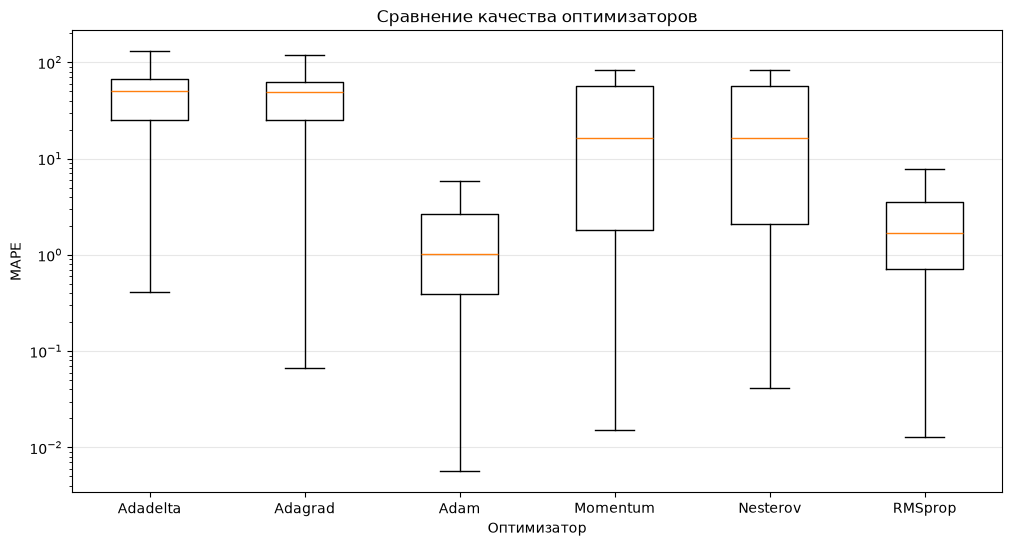

In [23]:
plot_MAPE_optimizer(df)

Сравнение оптимизаторов показывает, что наилучшую минимальную оценку MAPE дали оптимизаторы Adam и RMSprop. Также в среднем они дают лучше качество.

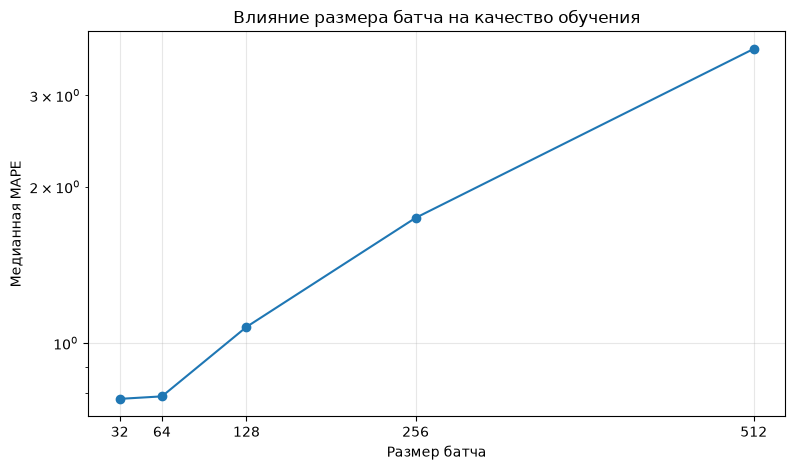

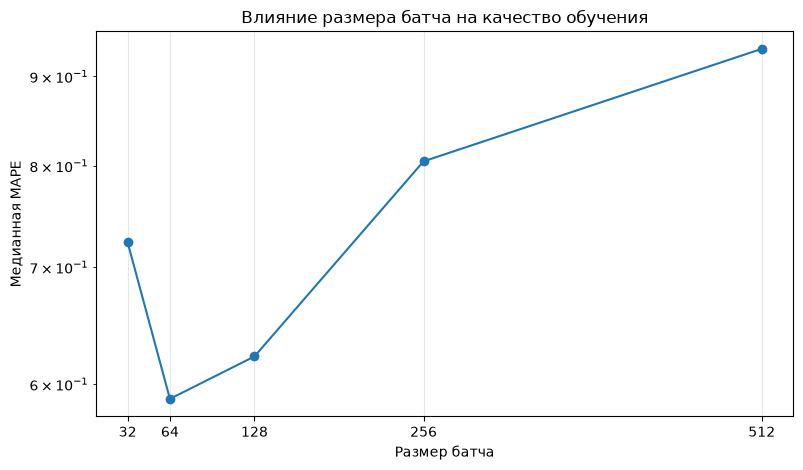

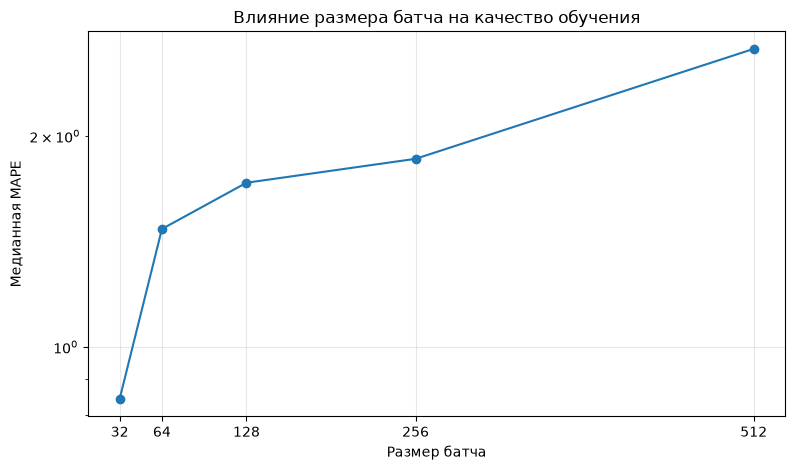

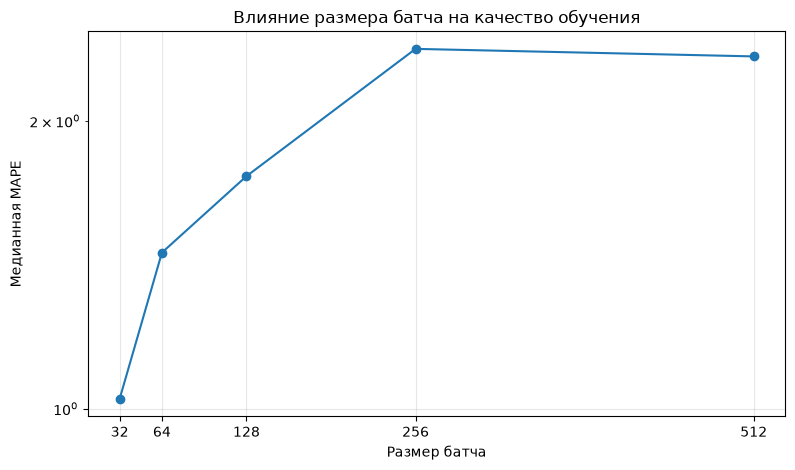

In [4]:
plot_MAPE_batch(df, "Adam", "MSELoss")
plot_MAPE_batch(df, "Adam", "L1Loss")
plot_MAPE_batch(df, "RMSprop", "MSELoss")
plot_MAPE_batch(df, "RMSprop", "L1Loss")

Тут мне стало интересно рассмотреть влияние батча, можно легко увидеть что оценка ниже у батча 32, 64. Что интересно сочетание Adam + L1Loss + батч 32 дали качество хуже, чем при батче 64. Поэтому для дальнейшего обучения сетей оставлю размерность батча 64.

Далее интересно рассмотреть влияние функции активации на качетсво модели

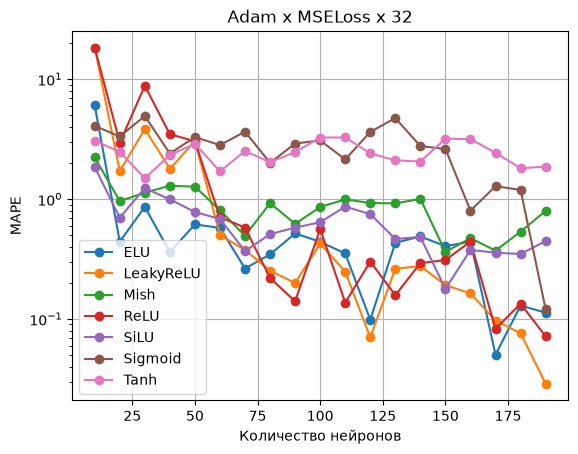

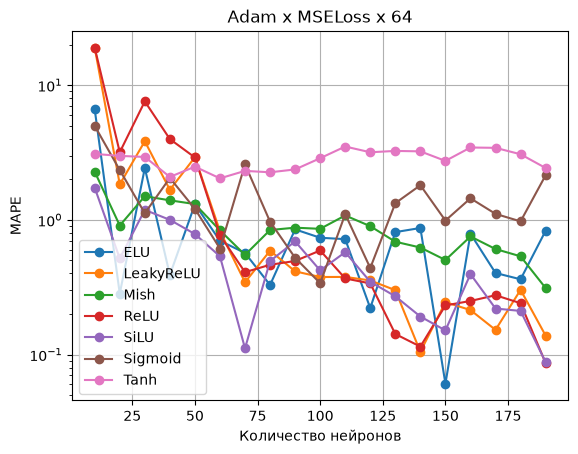

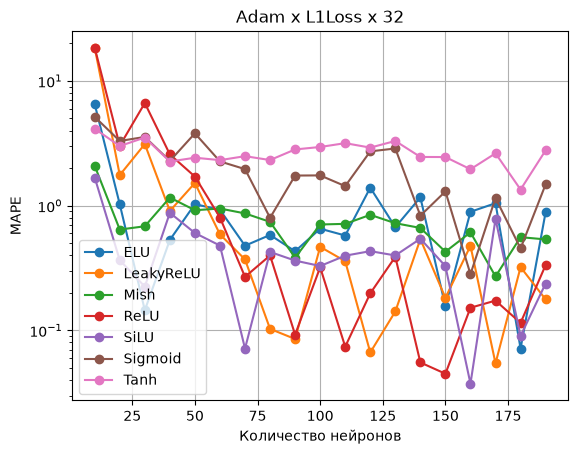

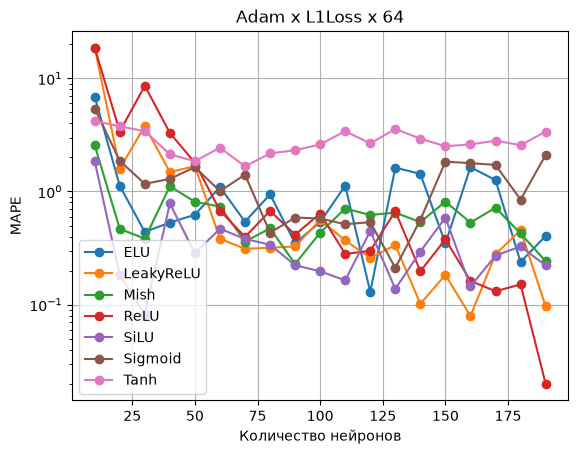

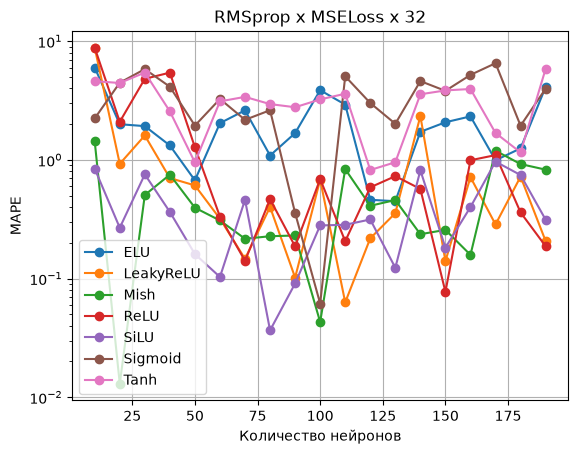

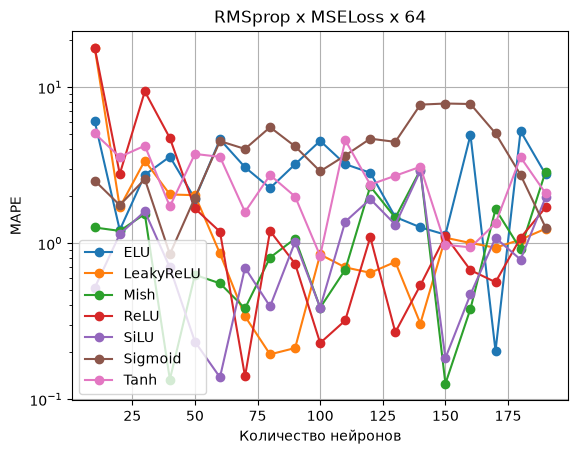

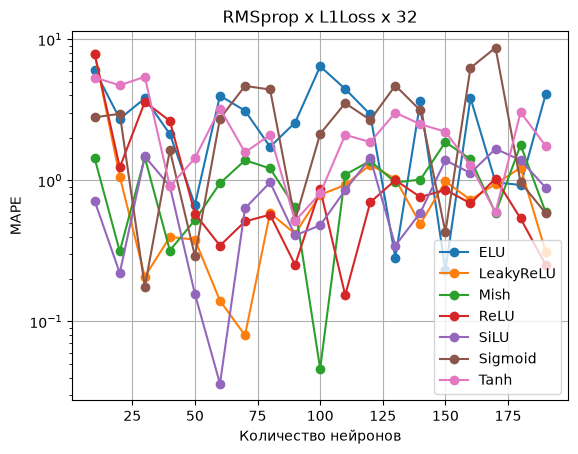

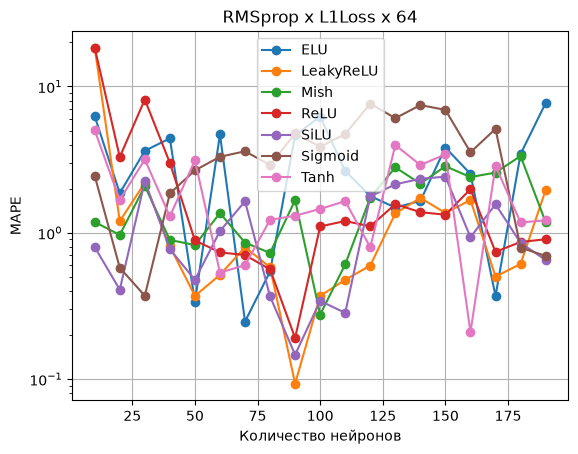

In [3]:
plot_MAPE_neurons(df, "Adam", "MSELoss", 32)
plot_MAPE_neurons(df, "Adam", "MSELoss", 64)
plot_MAPE_neurons(df, "Adam", "L1Loss", 32)
plot_MAPE_neurons(df, "Adam", "L1Loss", 64)

plot_MAPE_neurons(df, "RMSprop", "MSELoss", 32)
plot_MAPE_neurons(df, "RMSprop", "MSELoss", 64)
plot_MAPE_neurons(df, "RMSprop", "L1Loss", 32)
plot_MAPE_neurons(df, "RMSprop", "L1Loss", 64)

По графикам можно отметить для RMSprop, что минимум достигается в диапазоне от 50 до 150 нейронов, а при увелечении нейронов качество начинает падать.

По графикам выделяются 2 функции активации для Adam: SiLU и LeakyReLU. Также они хорошо приближают решение и для RMSprop. Также интересна функция Mish, которая хорошо показывает себя на разном количестве нейронов, и с разными функция потерь. Mish хорошо показывет себя для RMSprop, но не для Adam, и всё же оставим ее для дальнейшего обучения.

Дальше обучим трехслойные модели:
- оптимизаторы Adam и RMSprop
- количество батчей 32, 64, 128 (оставим 128 чтобы посмотреть как себя видет обучение на более крупных моделях)
- SiLU, LeakyReLU, Mish

In [8]:
df = pd.read_csv("results_MLP3.csv", sep=";")
print(df.shape)
print(df.head())
display(df.sort_values(["mape"]).head(15))

(6156, 10)
                 run_id                                       model_params  \
0  fb1917bfdaf1fecb884d  {'input_size': 1, 'one': 10, 'two': 10, 'out': 1}   
1  83e7887703245b475eea  {'input_size': 1, 'one': 10, 'two': 10, 'out': 1}   
2  7ae9fb3457d4f0863869  {'input_size': 1, 'one': 10, 'two': 10, 'out': 1}   
3  a6e4bb2915e293547ffe  {'input_size': 1, 'one': 10, 'two': 10, 'out': 1}   
4  6324d3f0a0f6d1ff309c  {'input_size': 1, 'one': 10, 'two': 10, 'out': 1}   

  model_loss       func optimizer_class  epochs  batch_size  neurons  \
0    MSELoss  LeakyReLU         RMSprop     200         128       20   
1    MSELoss  LeakyReLU            Adam     200         128       20   
2    MSELoss       SiLU         RMSprop     200          64       20   
3    MSELoss  LeakyReLU         RMSprop     200          64       20   
4    MSELoss       SiLU         RMSprop     200         128       20   

       loss      mape  
0  0.000017  3.808655  
1  0.000015  2.521617  
2  0.000003  2.

,run_id,model_params,model_loss,func,optimizer_class,epochs,batch_size,neurons,loss,mape
1948,438ed4fa398b541c672e,"{'input_size': 1, 'one': 40, 'two': 30, 'out': 1}",L1Loss,Mish,Adam,200,32,70,1.605701e-04,0.002070
1093,0c335e431d91cb7fc012,"{'input_size': 1, 'one': 20, 'two': 130, 'out'...",MSELoss,SiLU,Adam,200,32,150,1.168132e-08,0.002198
2357,0c30b0bd852ff03b873f,"{'input_size': 1, 'one': 40, 'two': 150, 'out'...",MSELoss,Mish,RMSprop,200,32,190,1.317597e-07,0.002851
128,79cd3db7270f96db4dd5,"{'input_size': 1, 'one': 10, 'two': 40, 'out': 1}",MSELoss,Mish,Adam,200,32,50,7.642985e-08,0.002854
4749,c5be3f4a0eedba2a10a8,"{'input_size': 1, 'one': 100, 'two': 60, 'out'...",L1Loss,Mish,Adam,200,128,160,2.203514e-04,0.003010
3749,4ba8ea709c3be21a8ca1,"{'input_size': 1, 'one': 70, 'two': 110, 'out'...",L1Loss,Mish,Adam,200,32,180,2.118131e-04,0.003274
2349,3dbae1d4fc9b68150ee7,"{'input_size': 1, 'one': 40, 'two': 150, 'out'...",MSELoss,SiLU,RMSprop,200,32,190,1.537251e-07,0.003430
5696,d3fb339da1772b7d760f,"{'input_size': 1, 'one': 140, 'two': 30, 'out'...",MSELoss,SiLU,Adam,200,64,170,1.575418e-08,0.003797
1245,c4303c7ce8942874aebb,"{'input_size': 1, 'one': 20, 'two': 170, 'out'...",MSELoss,Mish,Adam,200,32,190,4.266212e-08,0.003934
4135,0cdcda10329b90d2bbf0,"{'input_size': 1, 'one': 80, 'two': 100, 'out'...",L1Loss,SiLU,Adam,200,32,180,2.258973e-04,0.004986


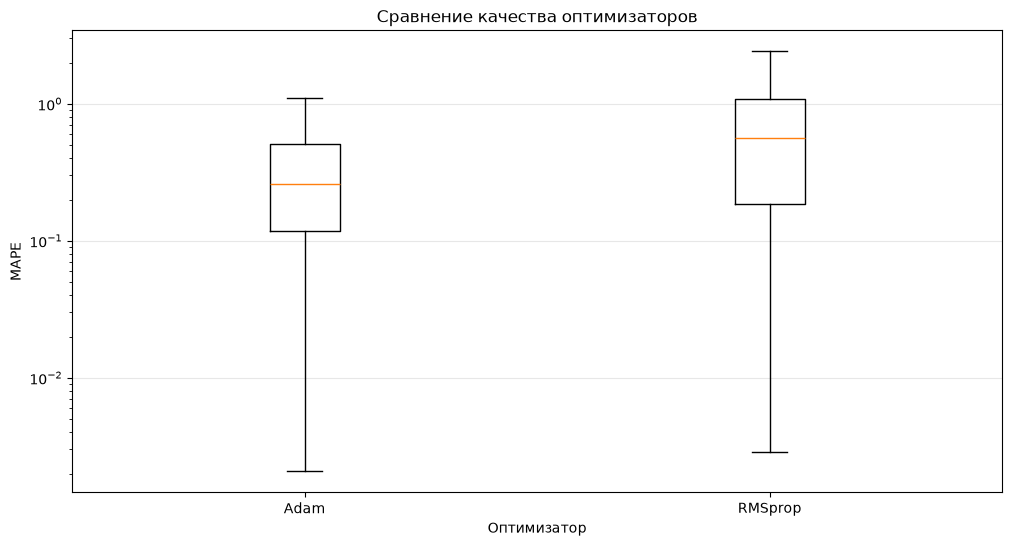

In [5]:
plot_MAPE_optimizer(df)

Adam показал себя лучше и на трехслойных моделях, как и по лучшему результату, так и в среднем.

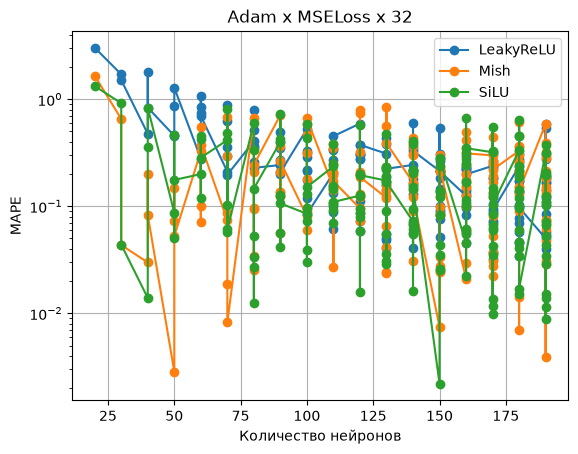

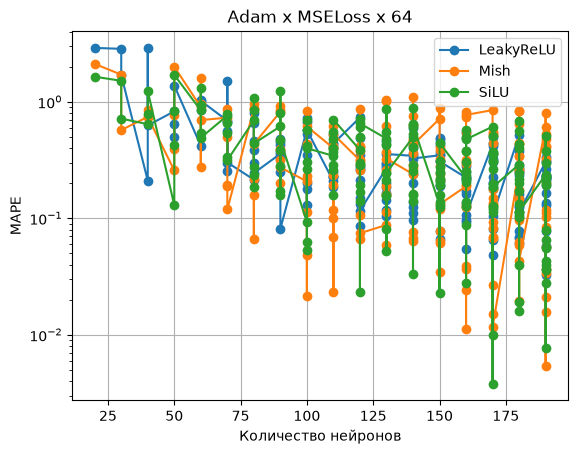

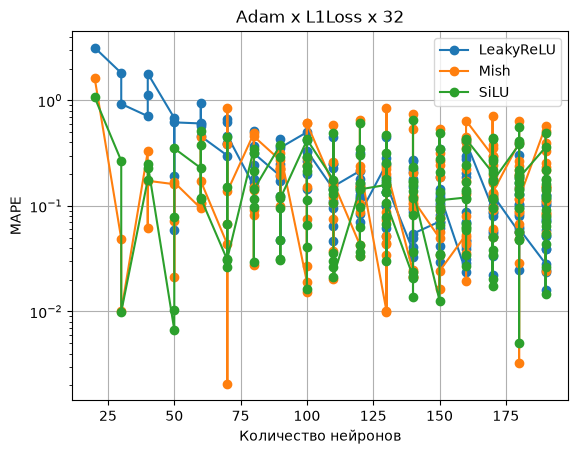

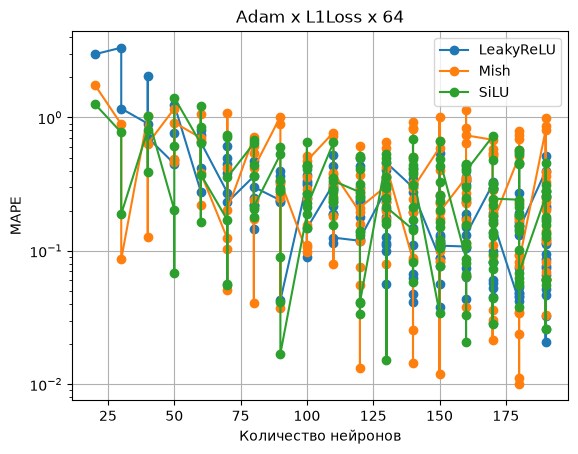

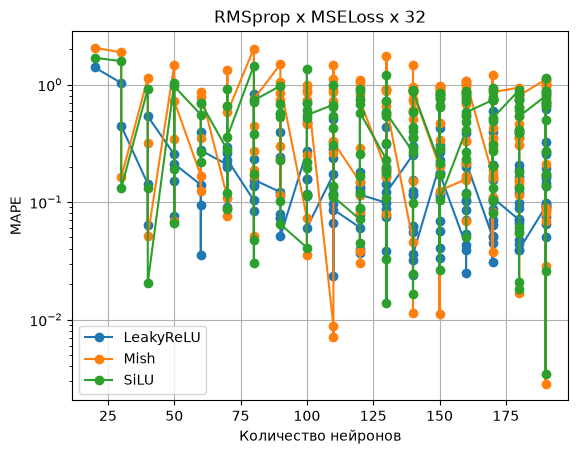

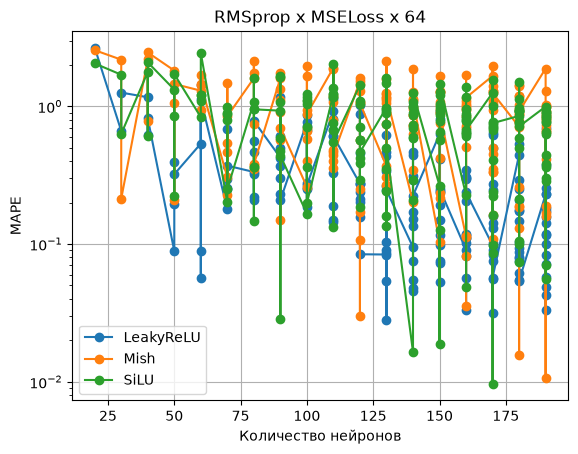

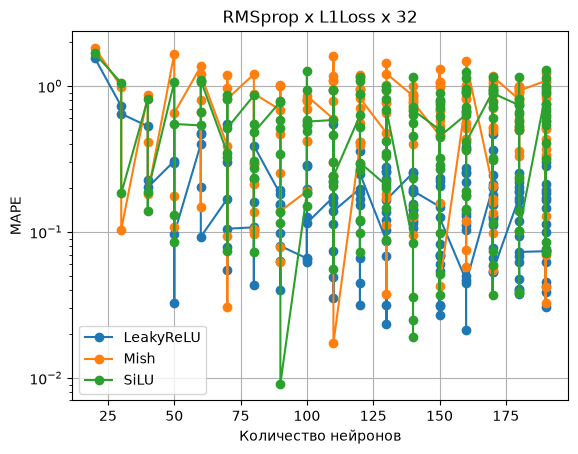

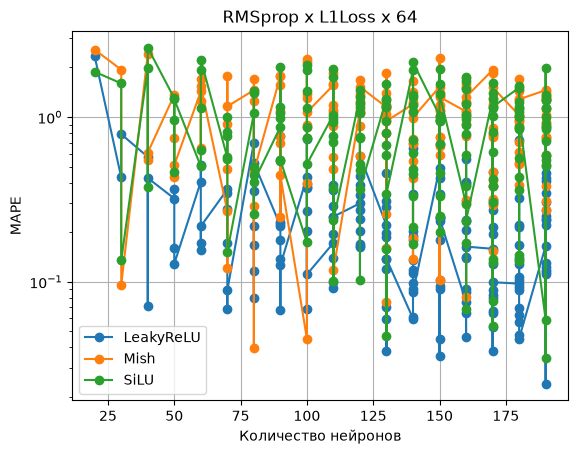

In [9]:
plot_MAPE_neurons(df, "Adam", "MSELoss", 32)
plot_MAPE_neurons(df, "Adam", "MSELoss", 64)
plot_MAPE_neurons(df, "Adam", "L1Loss", 32)
plot_MAPE_neurons(df, "Adam", "L1Loss", 64)

plot_MAPE_neurons(df, "RMSprop", "MSELoss", 32)
plot_MAPE_neurons(df, "RMSprop", "MSELoss", 64)
plot_MAPE_neurons(df, "RMSprop", "L1Loss", 32)
plot_MAPE_neurons(df, "RMSprop", "L1Loss", 64)

Промежуточный итог. LeakyReLU показал хорошие результаты на оптимизаторе RMSprop, но сам оптимизатор показал качество хуже в сравнении с Adam. С остальными двумя метриками не однозначно получается, поэтому их для дальнейшего обучения оставим. Также отмечу что batch 128 есть в топ 15 лучших резульатов, так что можно для дальнейшего обучения оставить такую размерность для исследования.

Конфигурации для дальнейшего исследования:
- Оптимизатор Adam
- размерность батчей 32, 64, 128
- Фунции активации Mish и SiLU
- Функции потерь оставляем также

Дальше думаю можно увеличить количество эпох (1000), вохможно модели просто не дообучились. Обучение будет производено на трехслойных моделях

In [5]:
df = pd.read_csv("results_MLP3_Adam.csv", sep=";")
print(df.shape)
print(df.head())
display(df.sort_values(["mape"]).head(15))

(2052, 10)
                 run_id                                       model_params  \
0  f8ca729a1c387269a5b0  {'input_size': 1, 'one': 10, 'two': 10, 'out': 1}   
1  5625bb8e7358177610cd  {'input_size': 1, 'one': 10, 'two': 10, 'out': 1}   
2  f8e60c85261c68b00414  {'input_size': 1, 'one': 10, 'two': 10, 'out': 1}   
3  18a578fd7458667ef0cd  {'input_size': 1, 'one': 10, 'two': 10, 'out': 1}   
4  57dad7871ea11ab8cadd  {'input_size': 1, 'one': 10, 'two': 10, 'out': 1}   

  model_loss  func optimizer_class  epochs  batch_size  neurons      loss  \
0    MSELoss  SiLU            Adam    1000         128       20  0.000002   
1    MSELoss  Mish            Adam    1000         128       20  0.000004   
2     L1Loss  SiLU            Adam    1000          64       20  0.000830   
3    MSELoss  Mish            Adam    1000          64       20  0.000002   
4    MSELoss  SiLU            Adam    1000          64       20  0.000002   

       mape  
0  1.690803  
1  2.203692  
2  1.185791  
3

,run_id,model_params,model_loss,func,optimizer_class,epochs,batch_size,neurons,loss,mape
1018,5b6f4bd8fe915f00d469,"{'input_size': 1, 'one': 60, 'two': 50, 'out': 1}",L1Loss,Mish,Adam,1000,64,110,0.000055,0.000258
1026,a20438cfa279387f2d72,"{'input_size': 1, 'one': 60, 'two': 60, 'out': 1}",L1Loss,SiLU,Adam,1000,64,120,0.000030,0.000360
574,156afee583aecd6226f7,"{'input_size': 1, 'one': 30, 'two': 130, 'out'...",L1Loss,SiLU,Adam,1000,32,160,0.000086,0.000397
1791,3372454572d6008b000a,"{'input_size': 1, 'one': 120, 'two': 70, 'out'...",L1Loss,SiLU,Adam,1000,128,190,0.000109,0.000531
1262,80ab7c54d49c8d372188,"{'input_size': 1, 'one': 80, 'two': 10, 'out': 1}",L1Loss,SiLU,Adam,1000,128,90,0.000107,0.000618
1066,cf982684ccefc80fd459,"{'input_size': 1, 'one': 60, 'two': 90, 'out': 1}",L1Loss,SiLU,Adam,1000,32,150,0.000041,0.000662
1299,199ee431d0ceb34aaffd,"{'input_size': 1, 'one': 80, 'two': 40, 'out': 1}",L1Loss,SiLU,Adam,1000,128,120,0.000093,0.000808
1104,4d2c2ef8726eb65565f3,"{'input_size': 1, 'one': 60, 'two': 120, 'out'...",L1Loss,Mish,Adam,1000,64,180,0.000068,0.000834
550,0b410b5016384d0c9d07,"{'input_size': 1, 'one': 30, 'two': 110, 'out'...",L1Loss,SiLU,Adam,1000,32,140,0.000078,0.000840
882,e4d02969b120c1910c8d,"{'input_size': 1, 'one': 50, 'two': 80, 'out': 1}",L1Loss,SiLU,Adam,1000,64,130,0.000117,0.000874


Достигнуто MAPE 0.000258 при конфигурации:
- архитектура НС {'input_size': 1, 'one': 60, 'two': 50, 'out': 1}
- функция потерь L1Loss
- функция активации Mish
- 1000 эпох

Но код не предусматривал переобучение и хотелось бы оценить скорость обучения конфигураций, которым удалось достичь порога MAPE 0.001

Model: {'input_size': 1, 'one': 60, 'two': 50, 'out': 1}, Func: Mish, Batch size: 64, L1Loss: 0.00013879280595574528, MAPE: 0.0016428969101980329


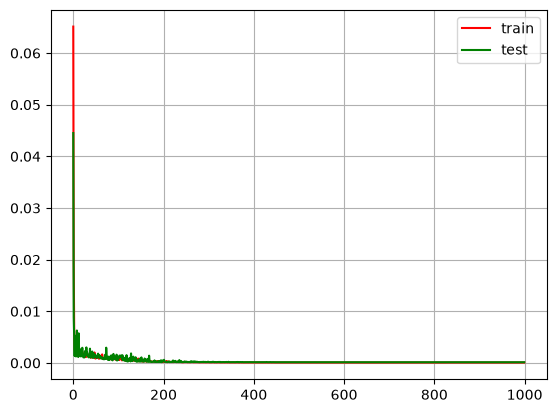

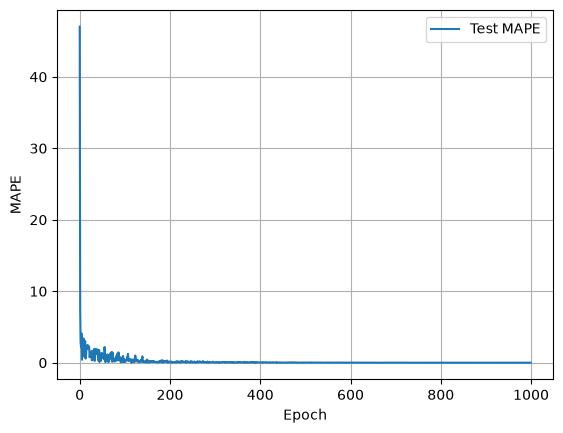

Model: {'input_size': 1, 'one': 60, 'two': 60, 'out': 1}, Func: SiLU, Batch size: 64, L1Loss: 0.00018841159180738032, MAPE: 0.18823041021823883


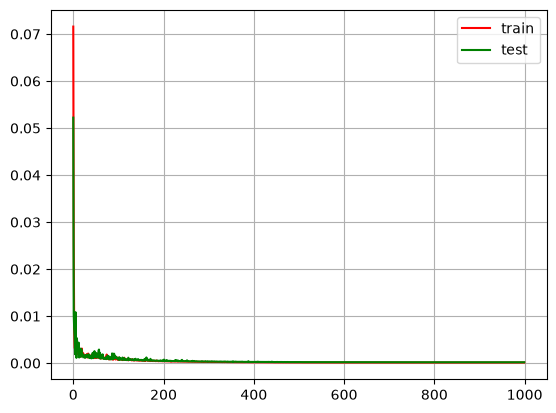

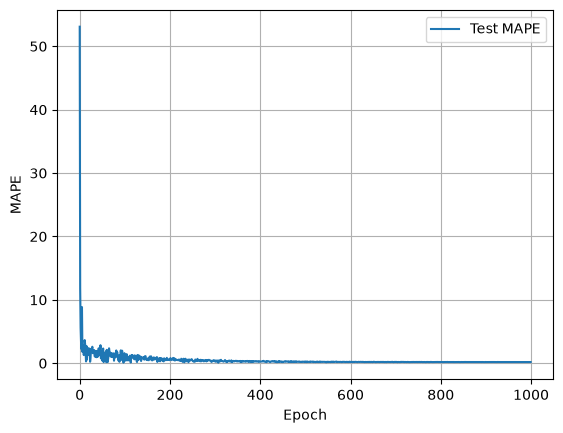

Model: {'input_size': 1, 'one': 30, 'two': 130, 'out': 1}, Func: SiLU, Batch size: 32, L1Loss: 6.0611371736740693e-05, MAPE: 0.011919710785150528


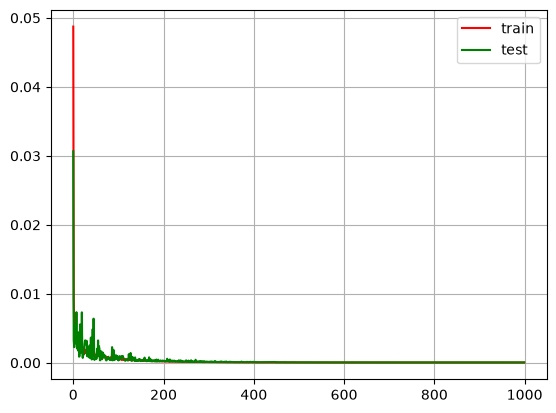

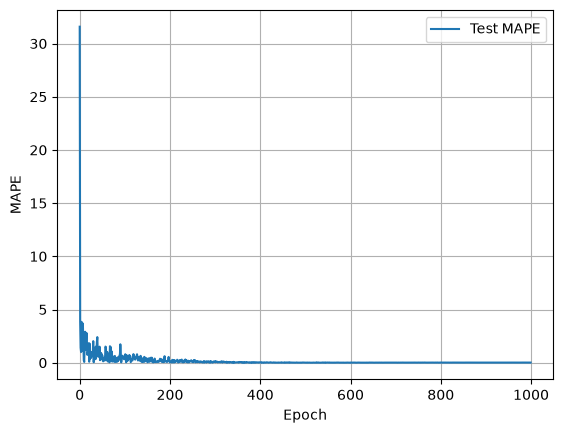

Model: {'input_size': 1, 'one': 120, 'two': 70, 'out': 1}, Func: SiLU, Batch size: 128, L1Loss: 7.532371091656387e-05, MAPE: 0.03804311901330948


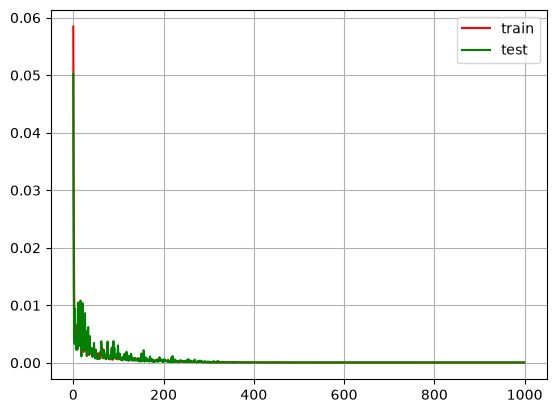

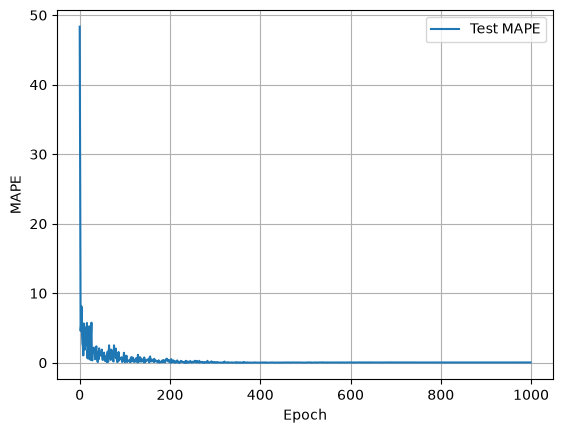

Model: {'input_size': 1, 'one': 80, 'two': 10, 'out': 1}, Func: SiLU, Batch size: 128, L1Loss: 0.00010604409908410162, MAPE: 0.07111244648694992


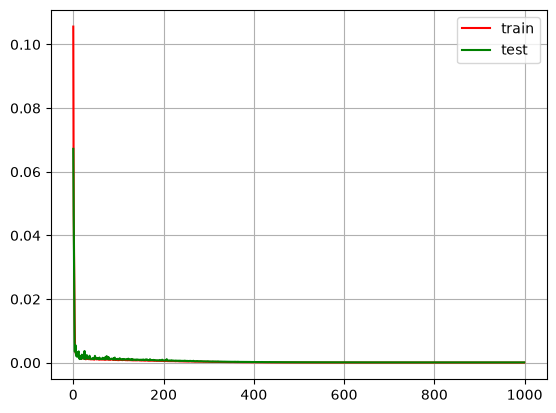

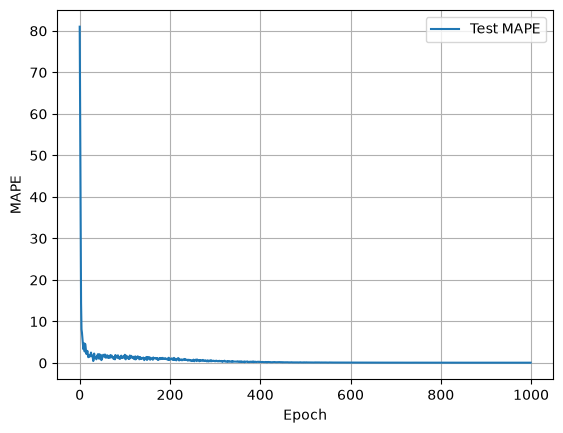

Model: {'input_size': 1, 'one': 60, 'two': 90, 'out': 1}, Func: SiLU, Batch size: 32, L1Loss: 0.00010333552199881524, MAPE: 0.0010986161651089787


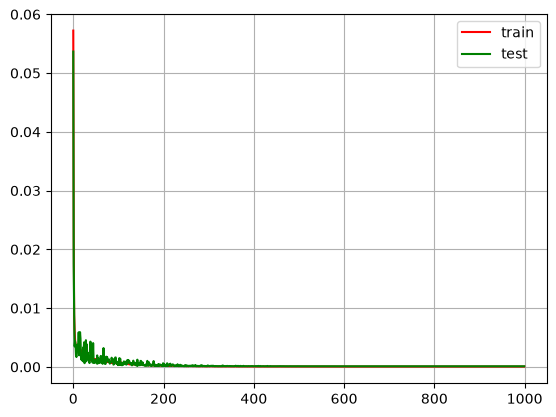

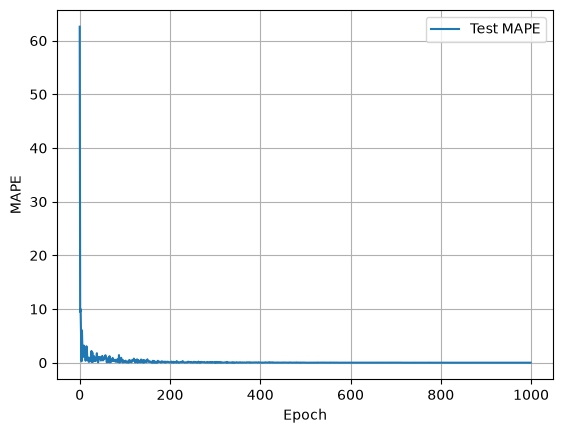

Model: {'input_size': 1, 'one': 80, 'two': 40, 'out': 1}, Func: SiLU, Batch size: 128, L1Loss: 0.00042599427979439497, MAPE: 0.35387513041496277


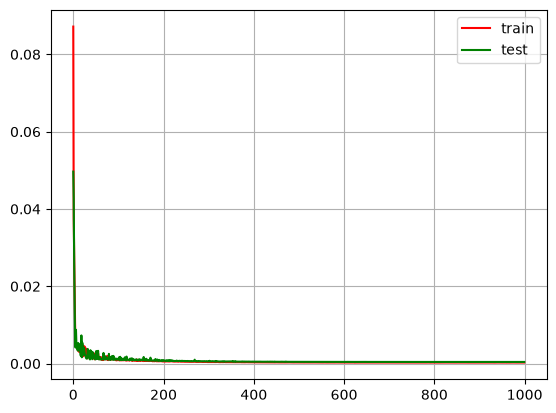

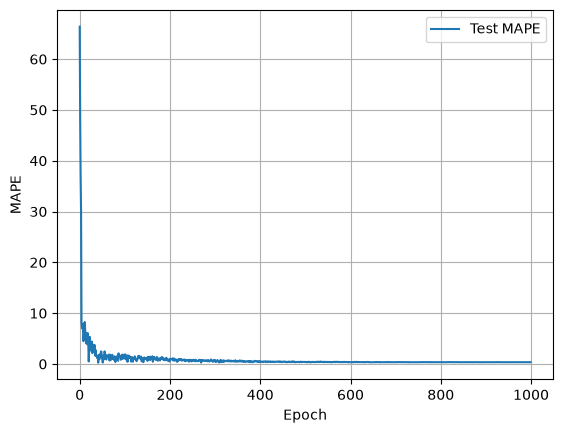

Model: {'input_size': 1, 'one': 60, 'two': 120, 'out': 1}, Func: Mish, Batch size: 64, L1Loss: 6.405245221685618e-05, MAPE: 0.0384342335164547


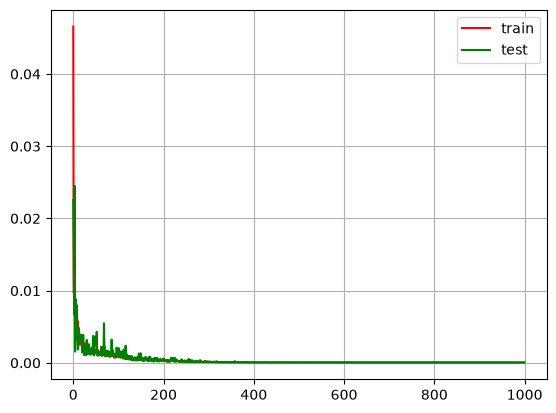

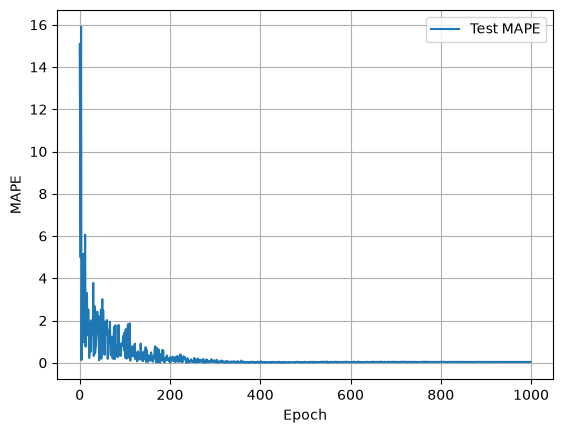

Model: {'input_size': 1, 'one': 30, 'two': 110, 'out': 1}, Func: SiLU, Batch size: 32, L1Loss: 5.21655056218151e-06, MAPE: 0.017672140151262283


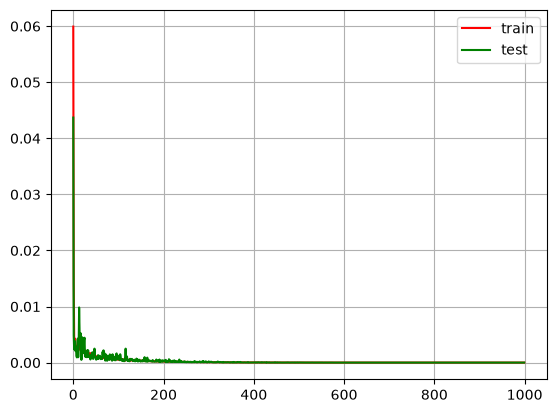

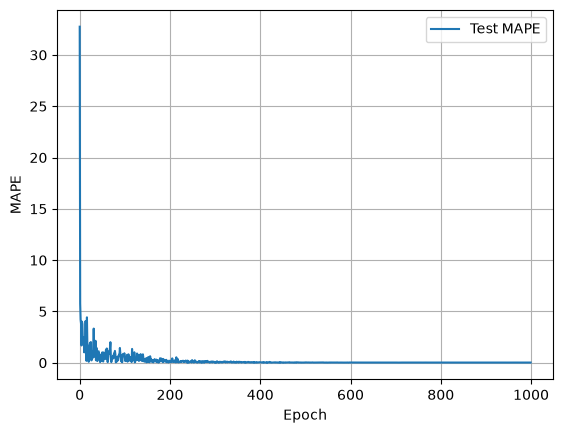

Model: {'input_size': 1, 'one': 50, 'two': 80, 'out': 1}, Func: SiLU, Batch size: 64, L1Loss: 0.00012024932220811024, MAPE: 0.0064535802230238914


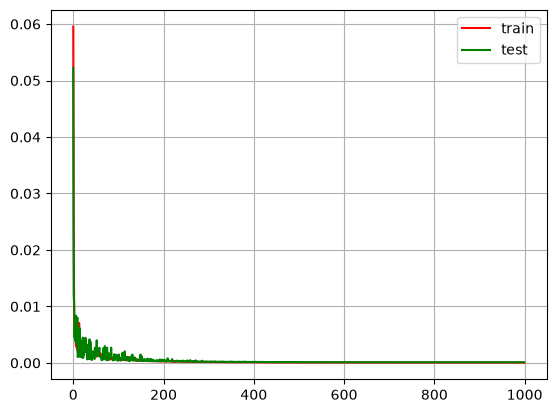

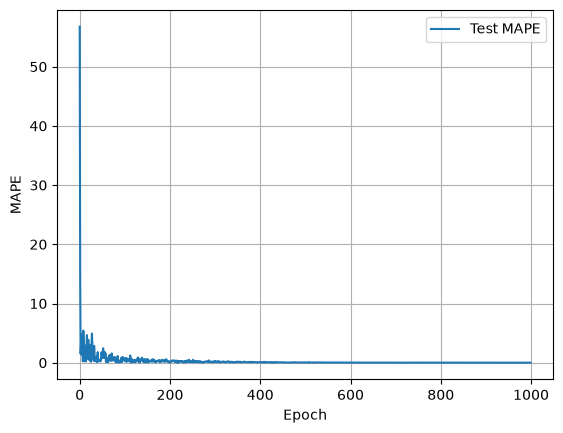

Model: {'input_size': 1, 'one': 10, 'two': 150, 'out': 1}, Func: Mish, Batch size: 32, L1Loss: 0.00040897211874835193, MAPE: 0.5079665184020996


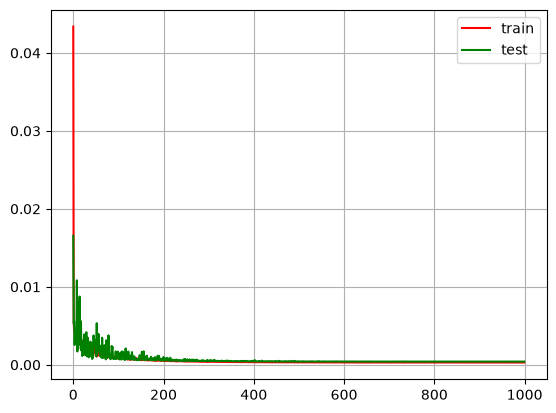

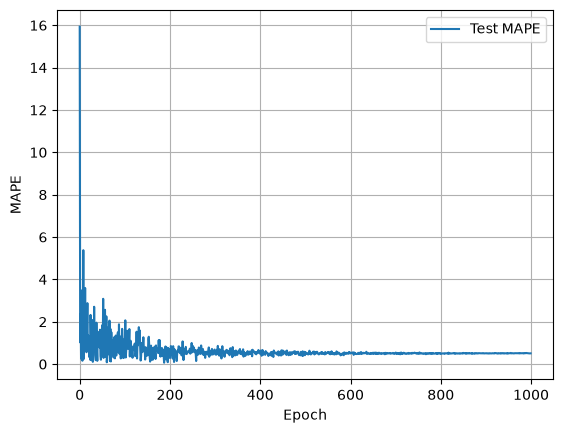

Model: {'input_size': 1, 'one': 120, 'two': 40, 'out': 1}, Func: Mish, Batch size: 128, L1Loss: 0.00017752681742422283, MAPE: 0.010233083739876747


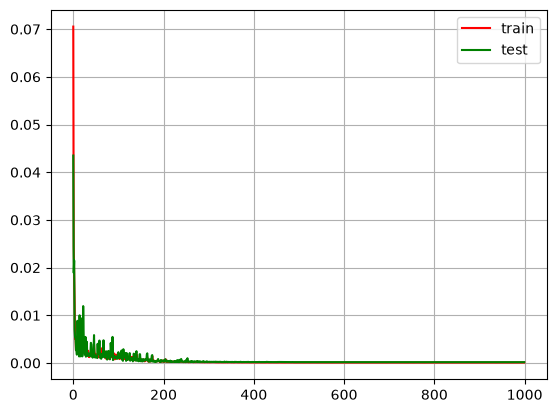

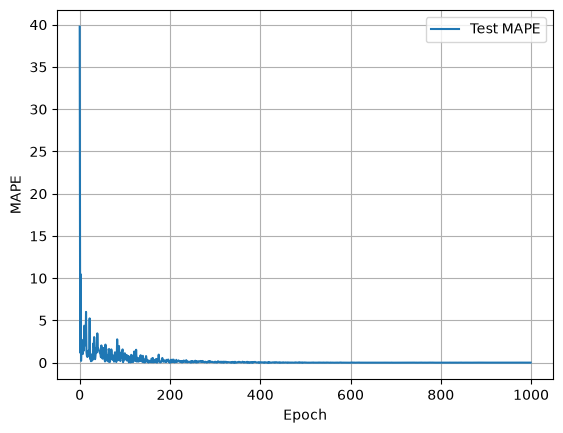

Model: {'input_size': 1, 'one': 140, 'two': 40, 'out': 1}, Func: Mish, Batch size: 32, L1Loss: 0.00010831522376975045, MAPE: 0.30722010135650635


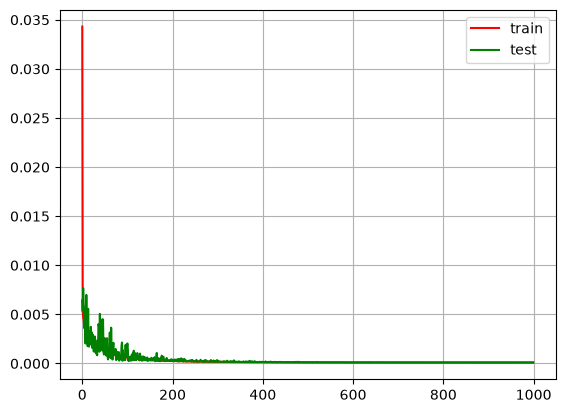

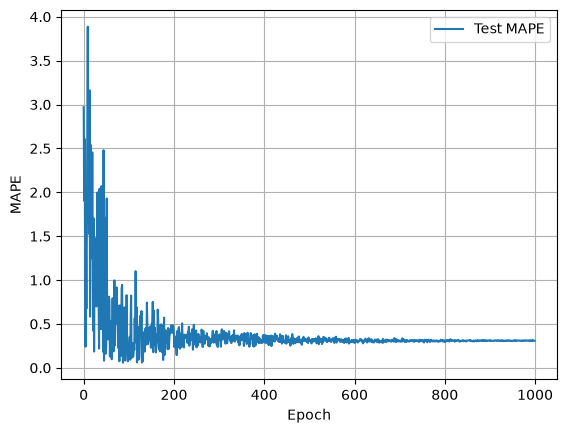

Model: {'input_size': 1, 'one': 70, 'two': 40, 'out': 1}, Func: SiLU, Batch size: 32, L1Loss: 7.953380554681644e-05, MAPE: 0.0340183787047863


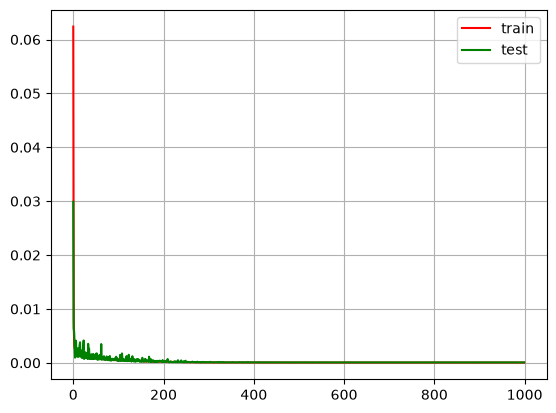

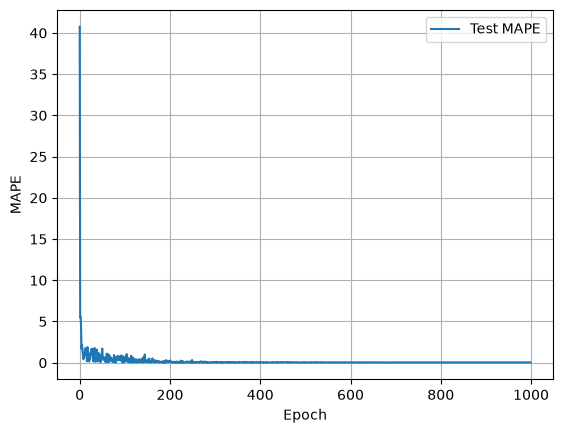

Model: {'input_size': 1, 'one': 70, 'two': 10, 'out': 1}, Func: SiLU, Batch size: 128, L1Loss: 7.165252463892102e-05, MAPE: 0.08900150656700134


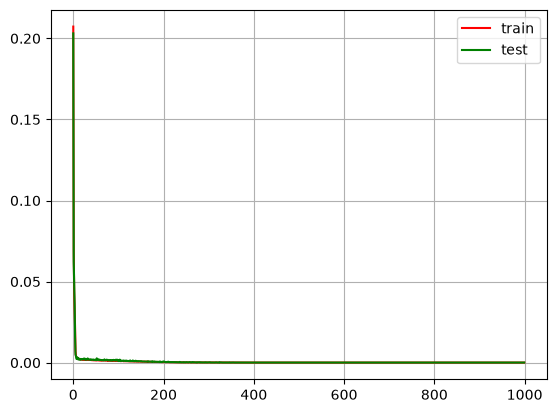

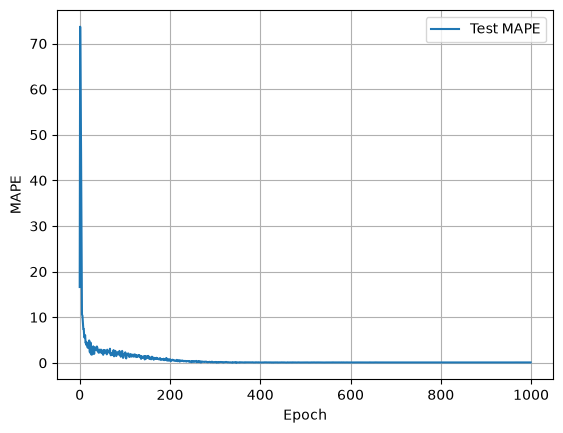

In [10]:
# Двуслойные модель
import ast

from data import Store

epochs = 1000
lr = 0.001
funcs = {
    "SiLU": nn.SiLU,
    "Mish": nn.Mish,
}
model_losses = {"MSELoss": nn.MSELoss(), "L1Loss": nn.L1Loss()}

store = Store("results.csv")
configurations = df.sort_values(["mape"]).head(15)

for _, config in configurations.iterrows():
    model_params = ast.literal_eval(config["model_params"])
    func = funcs[config["func"]]
    batch_size = config["batch_size"]

    model = MLP3(**model_params, func=func)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda=lambda epoch: math.exp(-0.01 * (epoch % epochs)),
    )
    train_errors, test_errors, test_mapes = run(
        model,
        model_losses[config["model_loss"]],
        optimizer,
        x_train,
        y_train,
        x_val,
        y_val,
        epochs,
        batch_size=batch_size,
        sampling=True,
        scheduler=scheduler,
    )
    print(
        f"Model: {model_params}, Func: {func.__name__}, Batch size: {batch_size}, {config['model_loss']}: {test_errors[-1][1]}, MAPE: {test_mapes[-1][1]}"
    )

    plt.figure("Errors")
    train_errors = np.array(train_errors)
    test_errors = np.array(test_errors)
    plt.plot(train_errors[:,0],train_errors[:,1],"r-",label = "train")
    plt.plot(test_errors[:,0],test_errors[:,1],"g-",label = "test")
    plt.legend()
    plt.grid()
    plt.show()

    test_mapes = np.array(test_mapes)
    plt.plot(test_mapes[:,0], test_mapes[:,1], label="Test MAPE")
    plt.xlabel("Epoch")
    plt.ylabel("MAPE")
    plt.legend()
    plt.grid()
    plt.show()

По графикам переобучения не вижу, все НС после 400 эпох уходят на "плато"